<a href="https://colab.research.google.com/github/Sanhith30/deepLearning-csa4704/blob/main/Lab%20Exp/CO5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Train: (10000, 784) Test: (1000, 784)

Brute-force free energy = -7.334564 | formula = -7.334564
Epoch  1: avg free energy =   -60.43 | reconstruction MSE = 0.0633
Epoch  2: avg free energy =   -81.16 | reconstruction MSE = 0.0541
Epoch  3: avg free energy =  -102.10 | reconstruction MSE = 0.0490
Epoch  4: avg free energy =  -115.74 | reconstruction MSE = 0.0459
Epoch  5: avg free energy =  -126.45 | reconstruction MSE = 0.0436
Epoch  6: avg free energy =  -137.46 | reconstruction MSE = 0.0419
Epoch  7: avg free energy =  -140.42 | reconstruction MSE = 0.0406
Epoch  8: avg free energy =  -149.18 | reconstruction MSE = 0.0394
Epoch  9: avg free energy =  -154.02 | reconstruction MSE = 0.0386
Epoch 10: avg free energy =  -160.56 | reconstruction MSE = 0.0378
Epoch 11: avg free energy =  -167.64 | reconstruction MSE = 0.0371
Epoch 12: avg free energy =  -170.29 | reconstruction MSE = 0.0366
Epoch 13: avg free energy =  -173.79 | reconstru

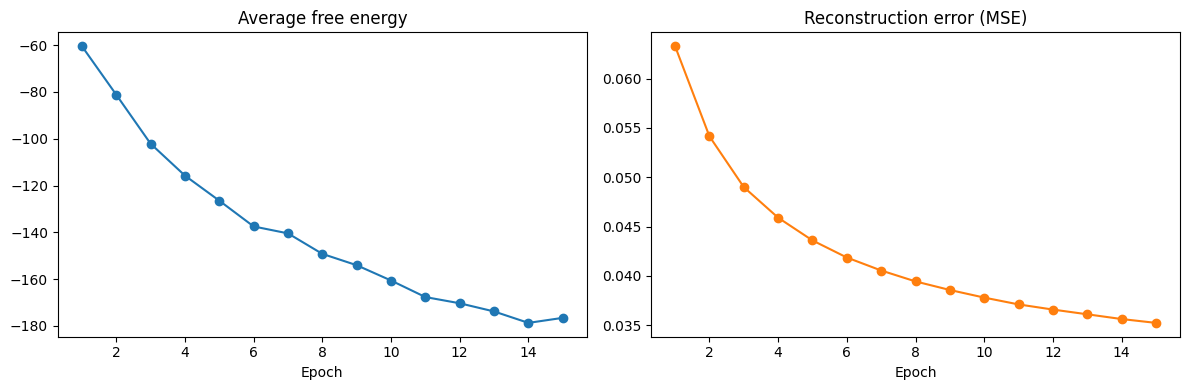


Test reconstruction MSE = 0.0361
Average energy E(v,h) of a test image with its most likely hidden state: -170.95


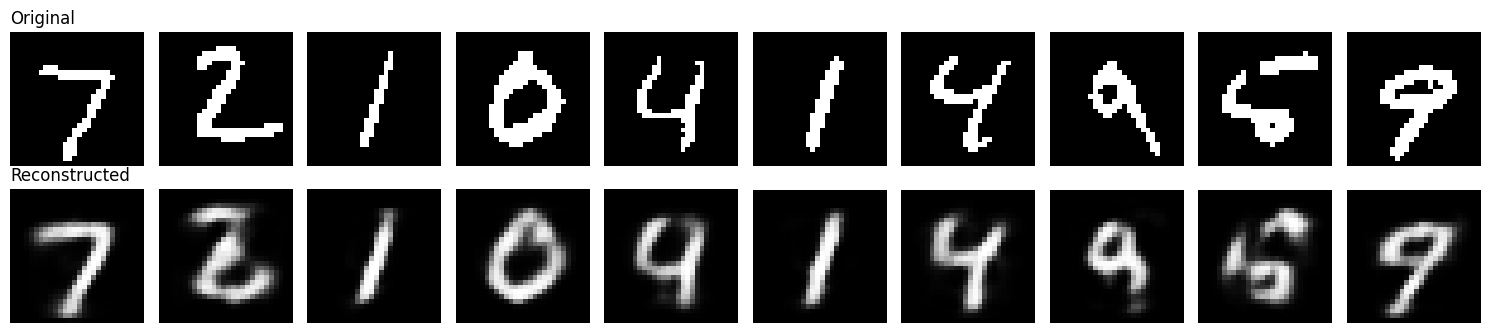

In [1]:
"""Experiment 25: Restricted Boltzmann Machine Energy and Reconstruction (binarised MNIST)"""
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import expit            # sigmoid
from itertools import product

rng = np.random.RandomState(0)

# ---------------- Data: binarised MNIST (784 visible units) ----------------
def load_mnist(n_train=10000, n_test=1000):
    try:
        from tensorflow import keras
        (x, _), (xt, _) = keras.datasets.mnist.load_data()
        x = x.reshape(-1, 784) / 255.0; xt = xt.reshape(-1, 784) / 255.0
    except Exception as e:                                         # offline fallback (8x8 digits scaled to 28x28)
        print("WARNING: MNIST not available (", type(e).__name__, ") -> using scikit-learn digits scaled to 28x28.")
        from sklearn.datasets import load_digits
        from scipy.ndimage import zoom
        d = load_digits().images / 16.0
        d = np.stack([zoom(im, 3.5, order=1) for im in d]).reshape(-1, 784)
        x, xt = d[:int(0.8 * len(d))], d[int(0.8 * len(d)):]
    return (x[:n_train] > 0.5).astype(float), (xt[:n_test] > 0.5).astype(float)

X_train, X_test = load_mnist()
print("Train:", X_train.shape, "Test:", X_test.shape)

class RBM:
    def __init__(self, n_visible, n_hidden, seed=0):
        r = np.random.RandomState(seed)
        self.W = r.normal(0, 0.01, (n_visible, n_hidden))
        self.a = np.zeros(n_visible)        # visible bias
        self.b = np.zeros(n_hidden)         # hidden bias

    # ---- Task 1: energy E(v,h) = -a^T v - b^T h - v^T W h ----
    def energy(self, v, h):
        return -(v @ self.a) - (h @ self.b) - np.sum((v @ self.W) * h, axis=1)

    # free energy F(v) = -a^T v - sum_j log(1 + exp(b_j + v^T W_j))   (hidden units summed out)
    def free_energy(self, v):
        return -(v @ self.a) - np.sum(np.logaddexp(0, v @ self.W + self.b), axis=1)

    # ---- Task 2: conditional probabilities ----
    def p_h_given_v(self, v): return expit(v @ self.W + self.b)
    def p_v_given_h(self, h): return expit(h @ self.W.T + self.a)

    # ---- Task 3: one-step contrastive divergence (CD-1) ----
    def cd1(self, v0, lr):
        ph0 = self.p_h_given_v(v0)
        h0 = (rng.rand(*ph0.shape) < ph0).astype(float)          # sample hidden states
        pv1 = self.p_v_given_h(h0)                               # reconstruction
        ph1 = self.p_h_given_v(pv1)
        B = len(v0)
        self.W += lr * (v0.T @ ph0 - pv1.T @ ph1) / B            # positive phase - negative phase
        self.a += lr * np.mean(v0 - pv1, axis=0)
        self.b += lr * np.mean(ph0 - ph1, axis=0)

    def reconstruct(self, v):
        return self.p_v_given_h(self.p_h_given_v(v))

# ---------------- Sanity check: free energy = -log sum_h exp(-E(v,h)) on a tiny RBM ----------------
tiny = RBM(6, 3, seed=1); tiny.W = rng.normal(0, 1, (6, 3)); tiny.a = rng.normal(0, 1, 6); tiny.b = rng.normal(0, 1, 3)
v_test = rng.randint(0, 2, (1, 6)).astype(float)
all_h = np.array(list(product([0, 1], repeat=3)), dtype=float)
brute = -np.log(sum(np.exp(-tiny.energy(v_test, h[None, :])[0]) for h in all_h))
print(f"\nBrute-force free energy = {brute:.6f} | formula = {tiny.free_energy(v_test)[0]:.6f}")

# ---------------- Task 3 & 4: training with CD-1; track free energy and reconstruction error ----------------
rbm = RBM(784, 64)
EPOCHS, BATCH, LR = 15, 100, 0.1
free_energy, recon_err = [], []
for ep in range(1, EPOCHS + 1):
    perm = rng.permutation(len(X_train))
    for i in range(0, len(X_train), BATCH):
        rbm.cd1(X_train[perm[i:i + BATCH]], LR)
    fe = rbm.free_energy(X_train[:2000]).mean()
    err = np.mean((X_train[:2000] - rbm.reconstruct(X_train[:2000])) ** 2)
    free_energy.append(fe); recon_err.append(err)
    print(f"Epoch {ep:2d}: avg free energy = {fe:8.2f} | reconstruction MSE = {err:.4f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(range(1, EPOCHS + 1), free_energy, "o-"); ax[0].set_title("Average free energy"); ax[0].set_xlabel("Epoch")
ax[1].plot(range(1, EPOCHS + 1), recon_err, "o-", color="C1"); ax[1].set_title("Reconstruction error (MSE)"); ax[1].set_xlabel("Epoch")
plt.tight_layout(); plt.show()

test_err = np.mean((X_test - rbm.reconstruct(X_test)) ** 2)
print(f"\nTest reconstruction MSE = {test_err:.4f}")
print(f"Average energy E(v,h) of a test image with its most likely hidden state: "
      f"{rbm.energy(X_test[:200], (rbm.p_h_given_v(X_test[:200]) > 0.5).astype(float)).mean():.2f}")

# ---------------- Task 5: original vs reconstruction ----------------
n = 10
rec = rbm.reconstruct(X_test[:n])
fig, axes = plt.subplots(2, n, figsize=(15, 3.4))
for i in range(n):
    axes[0, i].imshow(X_test[i].reshape(28, 28), cmap="gray"); axes[0, i].axis("off")
    axes[1, i].imshow(rec[i].reshape(28, 28), cmap="gray"); axes[1, i].axis("off")
axes[0, 0].set_title("Original", loc="left"); axes[1, 0].set_title("Reconstructed", loc="left")
plt.tight_layout(); plt.show()

Train: (5000, 784) Test: (500, 784)
CD-1   time=   6.9s  recon MSE=0.0557  PLL= -129.81
CD-5   time=  66.7s  recon MSE=0.0561  PLL= -155.23
CD-10  time=  30.4s  recon MSE=0.0567  PLL= -119.79
PCD    time=   6.0s  recon MSE=0.0665  PLL= -151.59


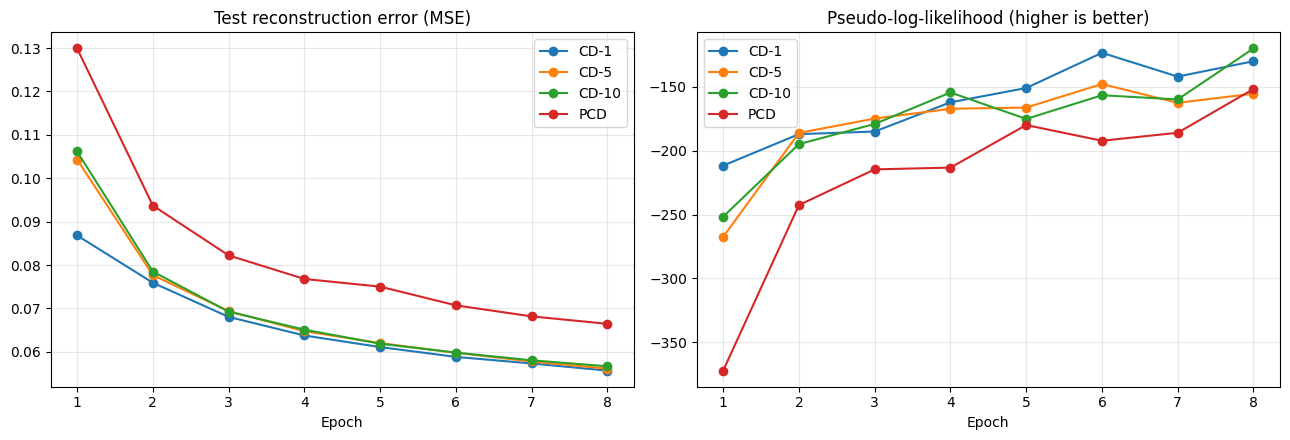

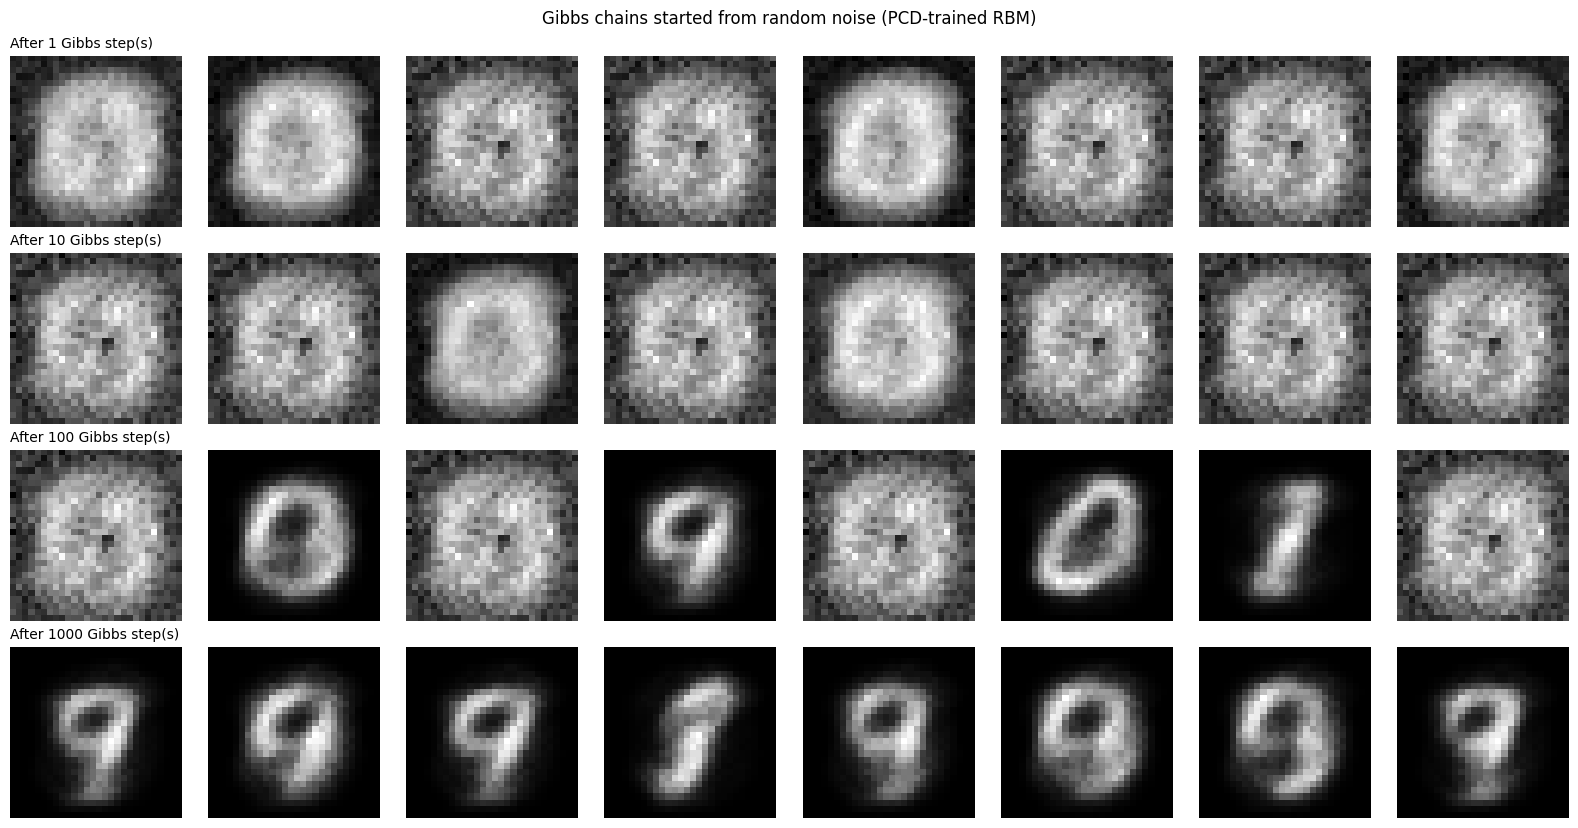

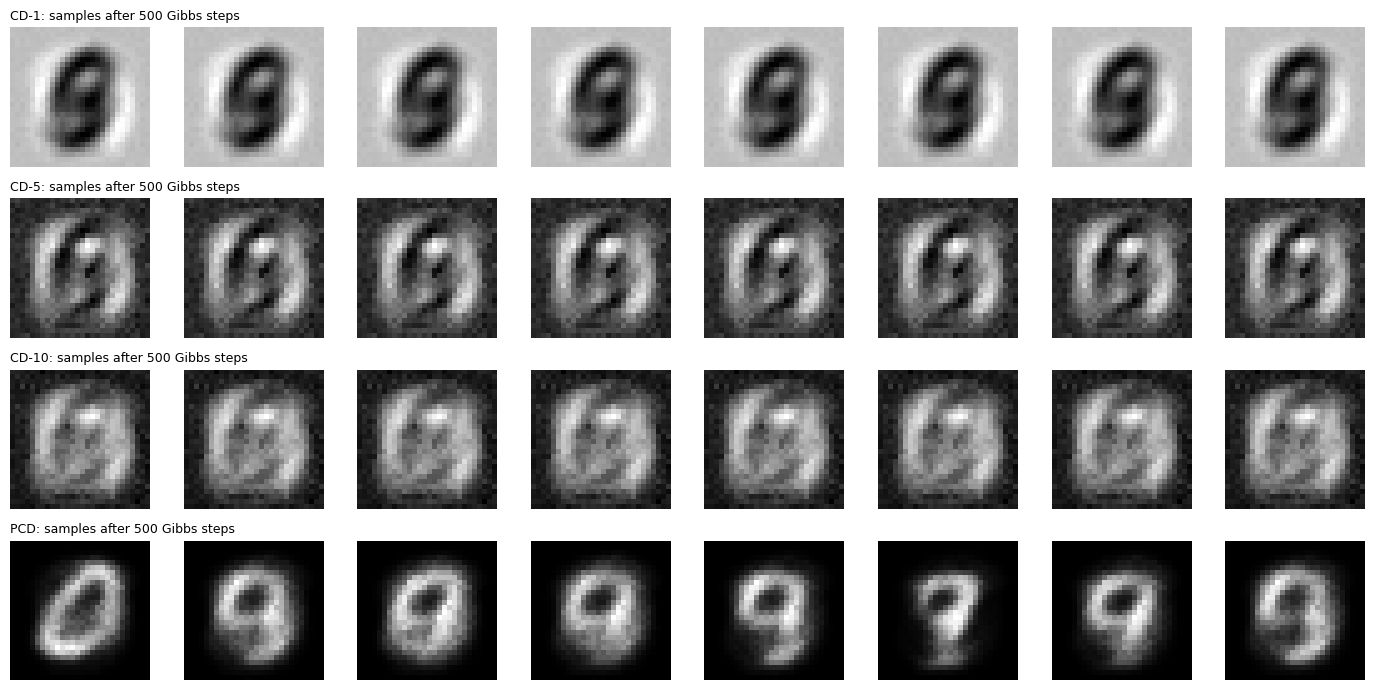


Method    Time (s)   Recon MSE       PLL
CD-1           6.9      0.0557   -129.81
CD-5          66.7      0.0561   -155.23
CD-10         30.4      0.0567   -119.79
PCD            6.0      0.0665   -151.59

Summary: CD-k cost grows roughly in proportion to k, while PCD costs about the same as CD-1 because its chain keeps running between updates. Compare the PLL and sample quality columns to decide whether the extra Gibbs steps were worth the time.


In [2]:
"""Experiment 26: Gibbs Sampling and Contrastive Divergence Analysis (CD-1, CD-5, CD-10, PCD)"""
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import expit

rng = np.random.RandomState(0)

def load_mnist(n_train=5000, n_test=500):
    try:
        from tensorflow import keras
        (x, _), (xt, _) = keras.datasets.mnist.load_data()
        x = x.reshape(-1, 784) / 255.0; xt = xt.reshape(-1, 784) / 255.0
    except Exception as e:
        print("WARNING: MNIST not available (", type(e).__name__, ") -> using scikit-learn digits scaled to 28x28.")
        from sklearn.datasets import load_digits
        from scipy.ndimage import zoom
        d = load_digits().images / 16.0
        d = np.stack([zoom(im, 3.5, order=1) for im in d]).reshape(-1, 784)
        x, xt = d[:int(0.8 * len(d))], d[int(0.8 * len(d)):]
    return (x[:n_train] > 0.5).astype(float), (xt[:n_test] > 0.5).astype(float)

X_train, X_test = load_mnist()
print("Train:", X_train.shape, "Test:", X_test.shape)

class RBM:
    def __init__(self, nv=784, nh=64):
        self.W = rng.normal(0, 0.01, (nv, nh)); self.a = np.zeros(nv); self.b = np.zeros(nh)
        self.chain = None                                           # persistent chain for PCD
    def p_h(self, v): return expit(v @ self.W + self.b)
    def p_v(self, h): return expit(h @ self.W.T + self.a)
    def sample(self, p): return (rng.rand(*p.shape) < p).astype(float)
    def free_energy(self, v): return -(v @ self.a) - np.sum(np.logaddexp(0, v @ self.W + self.b), axis=1)

    # ---- Task 1: block Gibbs sampling between the visible and hidden layers ----
    def gibbs(self, v, steps):
        for _ in range(steps):
            h = self.sample(self.p_h(v))
            v = self.sample(self.p_v(h))
        return v

    def train_batch(self, v0, lr, k, persistent=False):
        ph0 = self.p_h(v0)
        if persistent:                                              # PCD: continue the chain from the last update
            if self.chain is None:
                self.chain = v0.copy()
            vk = self.gibbs(self.chain, k); self.chain = vk
        else:                                                       # CD-k: start the chain at the data
            vk = self.gibbs(v0, k)
        phk = self.p_h(vk)
        B = len(v0)
        self.W += lr * (v0.T @ ph0 - vk.T @ phk) / B
        self.a += lr * np.mean(v0 - vk, axis=0)
        self.b += lr * np.mean(ph0 - phk, axis=0)

def recon_error(rbm, V):
    return np.mean((V - rbm.p_v(rbm.p_h(V))) ** 2)

def pseudo_log_likelihood(rbm, V):                                  # stochastic PLL estimate (flip one random bit per sample)
    idx = rng.randint(0, V.shape[1], len(V)); Vf = V.copy()
    Vf[np.arange(len(V)), idx] = 1 - Vf[np.arange(len(V)), idx]
    return V.shape[1] * np.mean(np.log(expit(rbm.free_energy(Vf) - rbm.free_energy(V)) + 1e-12))

# ---------------- Task 3 & 4: train CD-1, CD-5, CD-10, PCD ----------------
EPOCHS, BATCH, LR = 8, 100, 0.05
methods = {"CD-1": (1, False), "CD-5": (5, False), "CD-10": (10, False), "PCD": (1, True)}
results, models = {}, {}
for name, (k, pers) in methods.items():
    rbm = RBM(); rec, pll = [], []
    t0 = time.time()
    for ep in range(EPOCHS):
        perm = rng.permutation(len(X_train))
        for i in range(0, len(X_train) - BATCH + 1, BATCH):       # full batches only (PCD chain has fixed size)
            rbm.train_batch(X_train[perm[i:i + BATCH]], LR, k, pers)
        rec.append(recon_error(rbm, X_test)); pll.append(pseudo_log_likelihood(rbm, X_test))
    results[name] = {"recon": rec, "pll": pll, "time": time.time() - t0}
    models[name] = rbm
    print(f"{name:6} time={results[name]['time']:6.1f}s  recon MSE={rec[-1]:.4f}  PLL={pll[-1]:8.2f}")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for name, r in results.items():
    ax[0].plot(range(1, EPOCHS + 1), r["recon"], "o-", label=name); ax[1].plot(range(1, EPOCHS + 1), r["pll"], "o-", label=name)
ax[0].set_title("Test reconstruction error (MSE)"); ax[1].set_title("Pseudo-log-likelihood (higher is better)")
for a in ax:
    a.set_xlabel("Epoch"); a.legend(); a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

# ---------------- Task 2: Gibbs chains from random noise on a trained RBM ----------------
rbm = models["PCD"]
checkpoints = [1, 10, 100, 1000]
n_chains = 8
v = (rng.rand(n_chains, 784) < 0.5).astype(float)
snapshots, done = {}, 0
for cp in checkpoints:
    v = rbm.gibbs(v, cp - done); done = cp
    snapshots[cp] = rbm.p_v(rbm.sample(rbm.p_h(v)))                 # probabilities shown for a cleaner picture
fig, axes = plt.subplots(len(checkpoints), n_chains, figsize=(2 * n_chains, 2.1 * len(checkpoints)))
for r, cp in enumerate(checkpoints):
    for c in range(n_chains):
        axes[r, c].imshow(snapshots[cp][c].reshape(28, 28), cmap="gray"); axes[r, c].axis("off")
    axes[r, 0].set_title(f"After {cp} Gibbs step(s)", loc="left", fontsize=10)
plt.suptitle("Gibbs chains started from random noise (PCD-trained RBM)"); plt.tight_layout(); plt.show()

# ---------------- Task 5: training time vs sample quality ----------------
fig, axes = plt.subplots(len(methods), 8, figsize=(14, 7))
for r, (name, m) in enumerate(models.items()):
    s = rng.rand(8, 784) < 0.5
    s = m.gibbs(s.astype(float), 500)
    for c in range(8):
        axes[r, c].imshow(m.p_v(m.sample(m.p_h(s)))[c].reshape(28, 28), cmap="gray"); axes[r, c].axis("off")
    axes[r, 0].set_title(f"{name}: samples after 500 Gibbs steps", loc="left", fontsize=9)
plt.tight_layout(); plt.show()

print(f"\n{'Method':8}{'Time (s)':>10}{'Recon MSE':>12}{'PLL':>10}")
for name, r in results.items():
    print(f"{name:8}{r['time']:10.1f}{r['recon'][-1]:12.4f}{r['pll'][-1]:10.2f}")
print("\nSummary: CD-k cost grows roughly in proportion to k, while PCD costs about the same as CD-1 because its "
      "chain keeps running between updates. Compare the PLL and sample quality columns to decide whether the "
      "extra Gibbs steps were worth the time.")

Unlabelled: 20000 | labelled: 1000 | test: 10000
Pre-training RBM 1 (784 -> 500)
    epoch 2: recon MSE = 0.0238
    epoch 4: recon MSE = 0.0161
    epoch 6: recon MSE = 0.0127
    epoch 8: recon MSE = 0.0106
Pre-training RBM 2 (500 -> 250)
    epoch 2: recon MSE = 0.0216
    epoch 4: recon MSE = 0.0108
    epoch 6: recon MSE = 0.0070
    epoch 8: recon MSE = 0.0054
Pre-training time: 69.9s


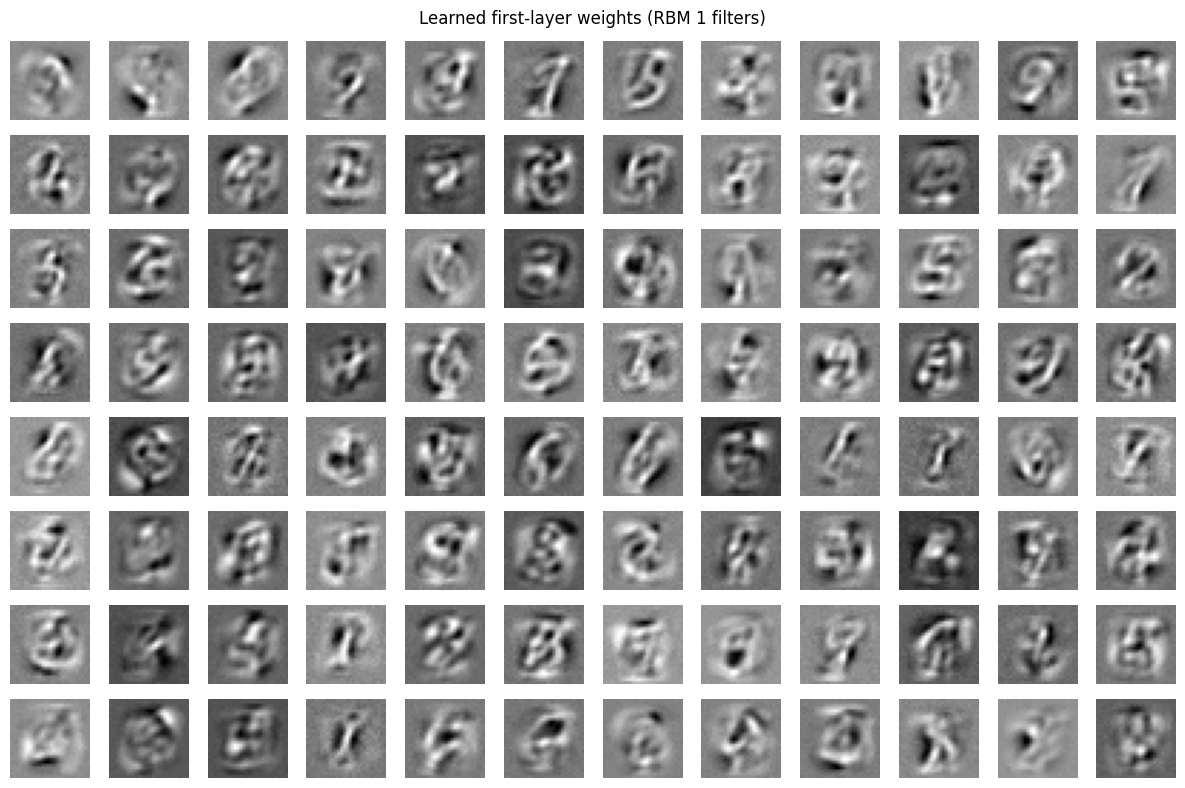


Test accuracy  | DBN pre-trained + fine-tuned : 0.9058
Test accuracy  | random initialisation        : 0.8775
Improvement from unsupervised pre-training    : +2.83 points


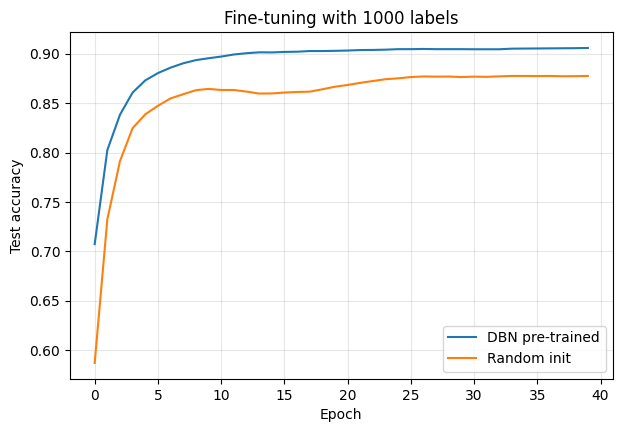

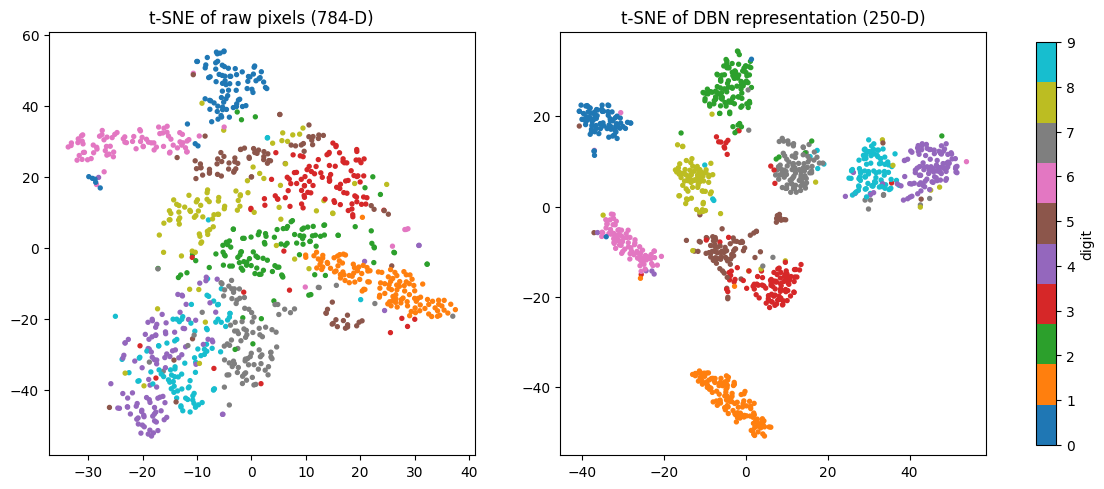

In [3]:
"""Experiment 27: Deep Belief Network Representation Learning (784-500-250, 1,000 labels)"""
import time
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from scipy.special import expit
from sklearn.manifold import TSNE

rng = np.random.RandomState(0); tf.random.set_seed(0)

def load_mnist():
    try:
        (x, y), (xt, yt) = keras.datasets.mnist.load_data()
        return x.reshape(-1, 784) / 255.0, y, xt.reshape(-1, 784) / 255.0, yt
    except Exception as e:
        print("WARNING: MNIST not available (", type(e).__name__, ") -> using scikit-learn digits scaled to 28x28.")
        from sklearn.datasets import load_digits
        from scipy.ndimage import zoom
        dg = load_digits(); d = np.stack([zoom(im / 16.0, 3.5, order=1) for im in dg.images]).reshape(-1, 784)
        cut = int(0.75 * len(d))
        return d[:cut], dg.target[:cut], d[cut:], dg.target[cut:]

x_all, y_all, x_test, y_test = load_mnist()
N_LAB = min(1000, len(x_all) // 3)
x_unl = x_all[:20000]                                               # unlabelled data for pre-training
x_lab, y_lab = x_all[:N_LAB], y_all[:N_LAB]                         # only N_LAB labels for fine-tuning
print(f"Unlabelled: {len(x_unl)} | labelled: {len(x_lab)} | test: {len(x_test)}")

class RBM:
    def __init__(self, nv, nh):
        self.W = rng.normal(0, 0.01, (nv, nh)); self.a = np.zeros(nv); self.b = np.zeros(nh)
    def p_h(self, v): return expit(v @ self.W + self.b)
    def p_v(self, h): return expit(h @ self.W.T + self.a)
    def fit(self, X, epochs=8, batch=100, lr=0.05):
        for ep in range(epochs):
            perm = rng.permutation(len(X))
            for i in range(0, len(X), batch):
                v0 = X[perm[i:i + batch]]
                ph0 = self.p_h(v0); h0 = (rng.rand(*ph0.shape) < ph0).astype(float)
                pv1 = self.p_v(h0); ph1 = self.p_h(pv1)
                self.W += lr * (v0.T @ ph0 - pv1.T @ ph1) / len(v0)
                self.a += lr * np.mean(v0 - pv1, axis=0); self.b += lr * np.mean(ph0 - ph1, axis=0)
            if ep % 2 == 1 or ep == epochs - 1:
                print(f"    epoch {ep+1}: recon MSE = {np.mean((X[:2000] - self.p_v(self.p_h(X[:2000]))) ** 2):.4f}")

# ---------------- Task 1: greedy layer-wise pre-training (784 -> 500 -> 250) ----------------
t0 = time.time()
print("Pre-training RBM 1 (784 -> 500)"); rbm1 = RBM(784, 500); rbm1.fit(x_unl)
h1 = rbm1.p_h(x_unl)
print("Pre-training RBM 2 (500 -> 250)"); rbm2 = RBM(500, 250); rbm2.fit(h1)
print(f"Pre-training time: {time.time() - t0:.1f}s")

# ---------------- Task 2: first-layer filters ----------------
fig, axes = plt.subplots(8, 12, figsize=(12, 8))
for i, a in enumerate(axes.ravel()):
    a.imshow(rbm1.W[:, i].reshape(28, 28), cmap="gray"); a.axis("off")
plt.suptitle("Learned first-layer weights (RBM 1 filters)"); plt.tight_layout(); plt.show()

# ---------------- Task 3 & 4: fine-tune pretrained network vs random initialisation ----------------
def make_net():
    m = keras.Sequential([layers.Input((784,)), layers.Dense(500, activation="sigmoid"),
                          layers.Dense(250, activation="sigmoid"), layers.Dense(10, activation="softmax")])
    m.compile(optimizer=keras.optimizers.Adam(0.001), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

dbn_net = make_net()
w = dbn_net.get_weights()
dbn_net.set_weights([rbm1.W, rbm1.b, rbm2.W, rbm2.b, w[4], w[5]])    # transfer RBM weights (output layer stays random)
rand_net = make_net()

EP = 40
h_dbn = dbn_net.fit(x_lab, y_lab, validation_data=(x_test, y_test), epochs=EP, batch_size=32, verbose=0)
h_rnd = rand_net.fit(x_lab, y_lab, validation_data=(x_test, y_test), epochs=EP, batch_size=32, verbose=0)
acc_dbn = dbn_net.evaluate(x_test, y_test, verbose=0)[1]; acc_rnd = rand_net.evaluate(x_test, y_test, verbose=0)[1]

# ---------------- Task 5: compare accuracy and plot representations ----------------
print(f"\nTest accuracy  | DBN pre-trained + fine-tuned : {acc_dbn:.4f}")
print(f"Test accuracy  | random initialisation        : {acc_rnd:.4f}")
print(f"Improvement from unsupervised pre-training    : {(acc_dbn - acc_rnd) * 100:+.2f} points")

plt.figure(figsize=(7, 4.5))
plt.plot(h_dbn.history["val_accuracy"], label="DBN pre-trained"); plt.plot(h_rnd.history["val_accuracy"], label="Random init")
plt.xlabel("Epoch"); plt.ylabel("Test accuracy"); plt.title(f"Fine-tuning with {len(x_lab)} labels"); plt.legend(); plt.grid(alpha=0.3); plt.show()

n_vis = min(1000, len(x_test))
feat_model = keras.Model(dbn_net.inputs, dbn_net.layers[1].output)    # 250-D representation
Z_dbn = feat_model.predict(x_test[:n_vis], verbose=0)
fig, ax = plt.subplots(1, 2, figsize=(13, 5.5))
for a, data, title in zip(ax, [x_test[:n_vis], Z_dbn], ["t-SNE of raw pixels (784-D)", "t-SNE of DBN representation (250-D)"]):
    emb = TSNE(n_components=2, random_state=0, init="pca").fit_transform(data)
    sc = a.scatter(emb[:, 0], emb[:, 1], c=y_test[:n_vis], cmap="tab10", s=8); a.set_title(title)
plt.colorbar(sc, ax=ax, fraction=0.02, label="digit"); plt.show()

Train: (8000, 784) Test: (1000, 784)
DBM epoch  1: test reconstruction MSE = 0.0543
DBM epoch  2: test reconstruction MSE = 0.0510
DBM epoch  3: test reconstruction MSE = 0.0493
DBM epoch  4: test reconstruction MSE = 0.0478
DBM epoch  5: test reconstruction MSE = 0.0473
DBM epoch  6: test reconstruction MSE = 0.0466
DBM epoch  7: test reconstruction MSE = 0.0462
DBM epoch  8: test reconstruction MSE = 0.0456
DBM epoch  9: test reconstruction MSE = 0.0452
DBM epoch 10: test reconstruction MSE = 0.0450


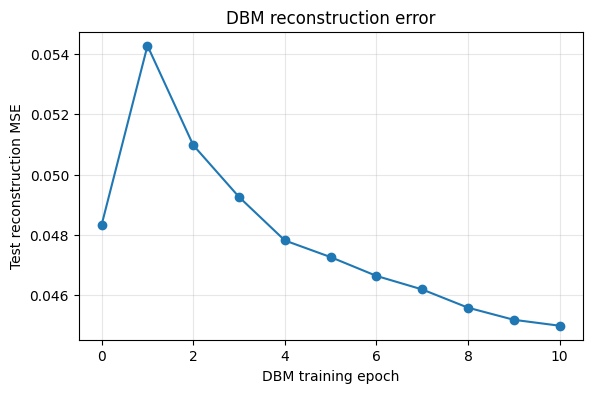

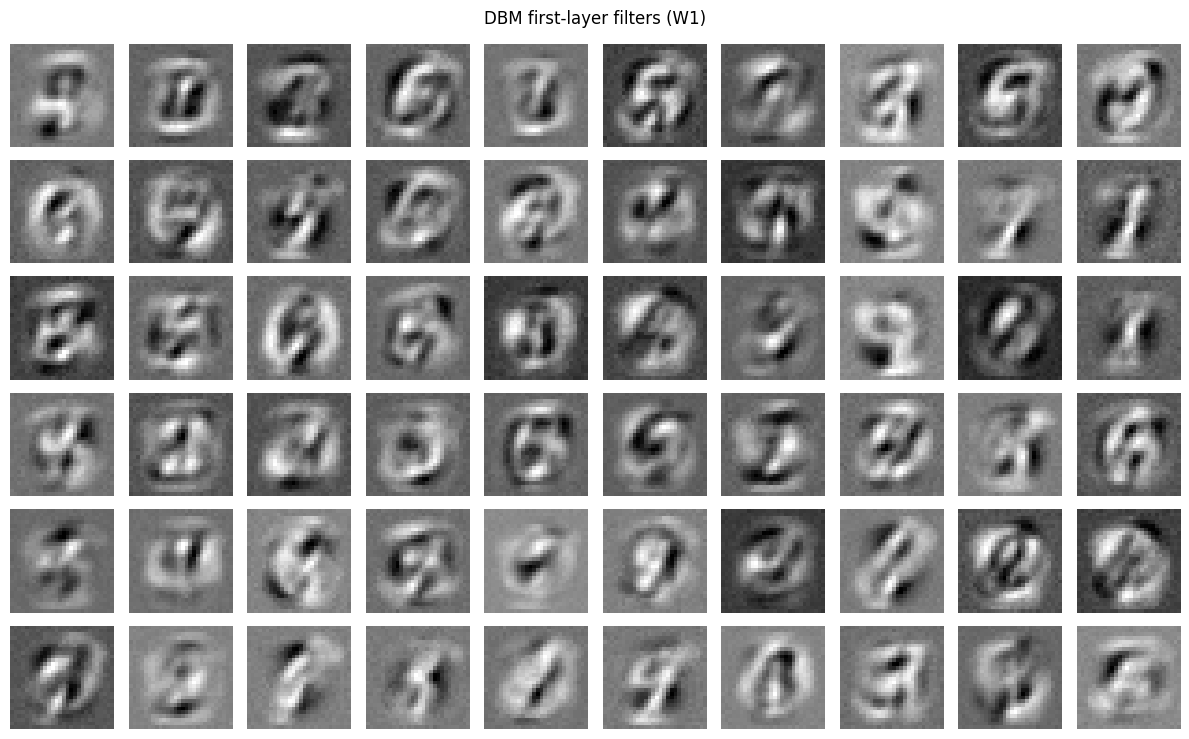

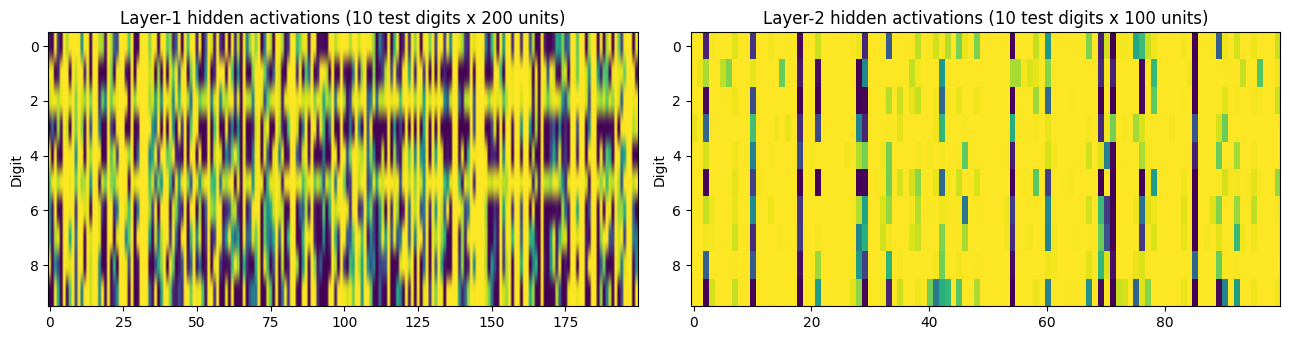

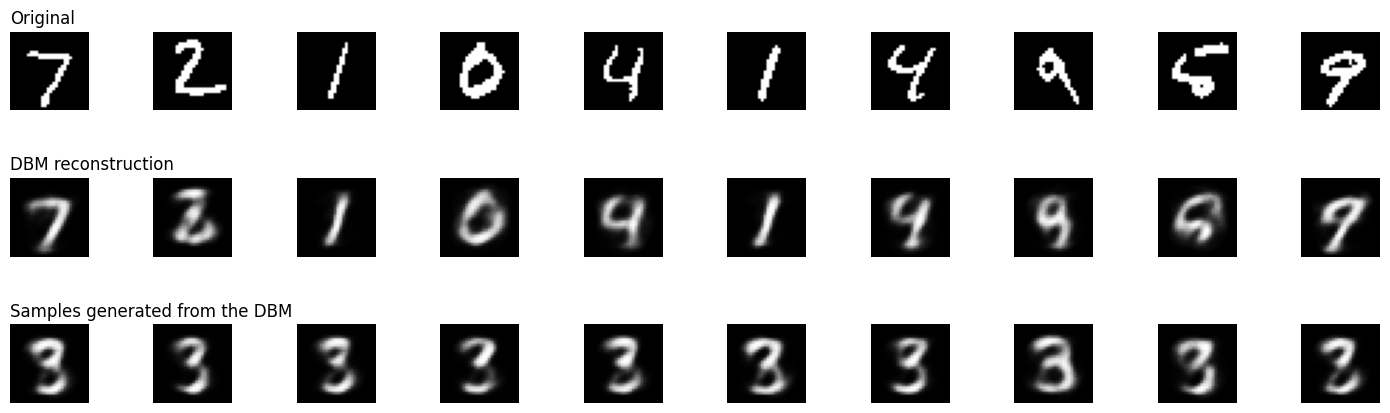


Test reconstruction MSE | single-layer RBM (200 hidden): 0.0307
Test reconstruction MSE | two-layer DBM (200+100 hidden)  : 0.0450
Note: reconstruction error measures how well layer 1 re-creates the input; the DBM's second layer mainly adds a richer generative model (top-down feedback), not necessarily a lower reconstruction error.


In [4]:
"""Experiment 28: Deep Boltzmann Machine Simulation (two hidden layers, mean-field + Gibbs)"""
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import expit

rng = np.random.RandomState(0)

def load_mnist(n_train=8000, n_test=1000):
    try:
        from tensorflow import keras
        (x, _), (xt, _) = keras.datasets.mnist.load_data()
        x = x.reshape(-1, 784) / 255.0; xt = xt.reshape(-1, 784) / 255.0
    except Exception as e:
        print("WARNING: MNIST not available (", type(e).__name__, ") -> using scikit-learn digits scaled to 28x28.")
        from sklearn.datasets import load_digits
        from scipy.ndimage import zoom
        d = load_digits().images / 16.0
        d = np.stack([zoom(im, 3.5, order=1) for im in d]).reshape(-1, 784)
        x, xt = d[:int(0.8 * len(d))], d[int(0.8 * len(d)):]
    return (x[:n_train] > 0.5).astype(float), (xt[:n_test] > 0.5).astype(float)

X_train, X_test = load_mnist()
H1, H2, BATCH = 200, 100, 100
print("Train:", X_train.shape, "Test:", X_test.shape)

def sample(p): return (rng.rand(*p.shape) < p).astype(float)

class RBM:                                                          # used for greedy initialisation and as the baseline
    def __init__(self, nv, nh):
        self.W = rng.normal(0, 0.01, (nv, nh)); self.a = np.zeros(nv); self.b = np.zeros(nh)
    def p_h(self, v): return expit(v @ self.W + self.b)
    def p_v(self, h): return expit(h @ self.W.T + self.a)
    def fit(self, X, epochs, lr=0.05):
        for _ in range(epochs):
            perm = rng.permutation(len(X))
            for i in range(0, len(X), BATCH):
                v0 = X[perm[i:i + BATCH]]; ph0 = self.p_h(v0); pv1 = self.p_v(sample(ph0)); ph1 = self.p_h(pv1)
                self.W += lr * (v0.T @ ph0 - pv1.T @ ph1) / len(v0)
                self.a += lr * np.mean(v0 - pv1, axis=0); self.b += lr * np.mean(ph0 - ph1, axis=0)

PRE_EPOCHS, DBM_EPOCHS = 5, 10

# ---------------- Task 1a: greedy pre-training of the two layers ----------------
rbm1 = RBM(784, H1); rbm1.fit(X_train, PRE_EPOCHS)
rbm2 = RBM(H1, H2); rbm2.fit(sample(rbm1.p_h(X_train)), PRE_EPOCHS)

# ---------------- Task 1b: DBM with mean-field inference ----------------
# Energy: E(v,h1,h2) = -v'W1 h1 - h1'W2 h2 - a'v - b1'h1 - b2'h2
class DBM:
    def __init__(self, rbm1, rbm2):
        self.W1, self.a, self.b1 = rbm1.W.copy(), rbm1.a.copy(), rbm1.b.copy()
        self.W2, self.b2 = rbm2.W.copy(), rbm2.b.copy()
        self.particles = None

    def mean_field(self, v, iters=10):                              # approximate posterior q(h1,h2|v) = prod of Bernoulli(mu)
        mu1 = expit(v @ self.W1 + self.b1); mu2 = expit(mu1 @ self.W2 + self.b2)
        for _ in range(iters):
            mu1 = expit(v @ self.W1 + mu2 @ self.W2.T + self.b1)    # bottom-up AND top-down input
            mu2 = expit(mu1 @ self.W2 + self.b2)
        return mu1, mu2

    def gibbs_step(self, v, h1, h2):                                # alternate layers: h1 | v,h2  then  v,h2 | h1
        h1 = sample(expit(v @ self.W1 + h2 @ self.W2.T + self.b1))
        v = sample(expit(h1 @ self.W1.T + self.a))
        h2 = sample(expit(h1 @ self.W2 + self.b2))
        return v, h1, h2

    # ---- Task 2: approximate learning = mean-field (positive phase) + persistent Gibbs chains (negative phase) ----
    def train_batch(self, v, lr):
        mu1, mu2 = self.mean_field(v)
        if self.particles is None:
            self.particles = [sample(np.full((len(v), 784), 0.5)), sample(mu1), sample(mu2)]
        vp, h1p, h2p = self.gibbs_step(*self.particles); self.particles = [vp, h1p, h2p]
        B = len(v)
        self.W1 += lr * (v.T @ mu1 - vp.T @ h1p) / B
        self.W2 += lr * (mu1.T @ mu2 - h1p.T @ h2p) / B
        self.a += lr * np.mean(v - vp, axis=0)
        self.b1 += lr * np.mean(mu1 - h1p, axis=0); self.b2 += lr * np.mean(mu2 - h2p, axis=0)

    def reconstruct(self, v):
        mu1, _ = self.mean_field(v)
        return expit(mu1 @ self.W1.T + self.a)

dbm = DBM(rbm1, rbm2)
rbm_base = RBM(784, H1); rbm_base.fit(X_train, PRE_EPOCHS + DBM_EPOCHS)     # single-layer baseline, same total epochs
mse = lambda V, R: np.mean((V - R) ** 2)
hist = [mse(X_test, dbm.reconstruct(X_test))]
for ep in range(1, DBM_EPOCHS + 1):
    perm = rng.permutation(len(X_train))
    for i in range(0, len(X_train) - BATCH + 1, BATCH):             # full batches (the particle set has a fixed size)
        dbm.train_batch(X_train[perm[i:i + BATCH]], lr=0.005)
    hist.append(mse(X_test, dbm.reconstruct(X_test)))
    print(f"DBM epoch {ep:2d}: test reconstruction MSE = {hist[-1]:.4f}")

plt.figure(figsize=(6.5, 4)); plt.plot(range(0, DBM_EPOCHS + 1), hist, "o-"); plt.xlabel("DBM training epoch")
plt.ylabel("Test reconstruction MSE"); plt.title("DBM reconstruction error"); plt.grid(alpha=0.3); plt.show()

# ---------------- Task 3: filters and hidden-unit activations ----------------
fig, axes = plt.subplots(6, 10, figsize=(12, 7.5))
for i, a in enumerate(axes.ravel()):
    a.imshow(dbm.W1[:, i].reshape(28, 28), cmap="gray"); a.axis("off")
plt.suptitle("DBM first-layer filters (W1)"); plt.tight_layout(); plt.show()

mu1, mu2 = dbm.mean_field(X_test[:10])
fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))
ax[0].imshow(mu1, aspect="auto", cmap="viridis"); ax[0].set_title("Layer-1 hidden activations (10 test digits x 200 units)")
ax[1].imshow(mu2, aspect="auto", cmap="viridis"); ax[1].set_title("Layer-2 hidden activations (10 test digits x 100 units)")
for a in ax: a.set_ylabel("Digit")
plt.tight_layout(); plt.show()

# ---------------- Task 4: samples and reconstructions ----------------
v, h1, h2 = dbm.particles
for _ in range(500):
    v, h1, h2 = dbm.gibbs_step(v, h1, h2)
fig, axes = plt.subplots(3, 10, figsize=(14, 4.6))
rec = dbm.reconstruct(X_test[:10])
for i in range(10):
    axes[0, i].imshow(X_test[i].reshape(28, 28), cmap="gray"); axes[1, i].imshow(rec[i].reshape(28, 28), cmap="gray")
    axes[2, i].imshow(expit(h1[i] @ dbm.W1.T + dbm.a).reshape(28, 28), cmap="gray")
    for r in range(3): axes[r, i].axis("off")
axes[0, 0].set_title("Original", loc="left"); axes[1, 0].set_title("DBM reconstruction", loc="left"); axes[2, 0].set_title("Samples generated from the DBM", loc="left")
plt.tight_layout(); plt.show()

# ---------------- Task 5: compare with a single-layer RBM ----------------
rec_dbm = mse(X_test, dbm.reconstruct(X_test)); rec_rbm = mse(X_test, rbm_base.p_v(rbm_base.p_h(X_test)))
print(f"\nTest reconstruction MSE | single-layer RBM ({H1} hidden): {rec_rbm:.4f}")
print(f"Test reconstruction MSE | two-layer DBM ({H1}+{H2} hidden)  : {rec_dbm:.4f}")
print("Note: reconstruction error measures how well layer 1 re-creates the input; the DBM's second layer "
      "mainly adds a richer generative model (top-down feedback), not necessarily a lower reconstruction error.")

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training images: (60000, 28, 28, 1)
VAE epoch  1: total=320.77  reconstruction=315.70  KL=5.06
VAE epoch  2: total=273.29  reconstruction=267.39  KL=5.89
VAE epoch  3: total=269.47  reconstruction=263.49  KL=5.98
VAE epoch  4: total=267.47  reconstruction=261.44  KL=6.04
VAE epoch  5: total=266.28  reconstruction=260.20  KL=6.07
VAE epoch  6: total=265.32  reconstruction=259.22  KL=6.10
VAE epoch  7: total=264.46  reconstruction=258.33  KL=6.13
VAE epoch  8: total=263.83  reconstruction=257.66  KL=6.17
VAE epoch  9: total=263.42  reconstruction=257.21  KL=6.21
VAE epoch 10: total=262.88  reconstruction=256.68  KL=6.21
VAE epoch 11: total=262.41  reconstruction=256.17  KL=6.24
VAE epoch 12: total=262.03  reconstruction=255.75  KL=6.28
VAE epoch 13: total=261.78  reconstruction=255.51  KL=6.27
VAE epoch

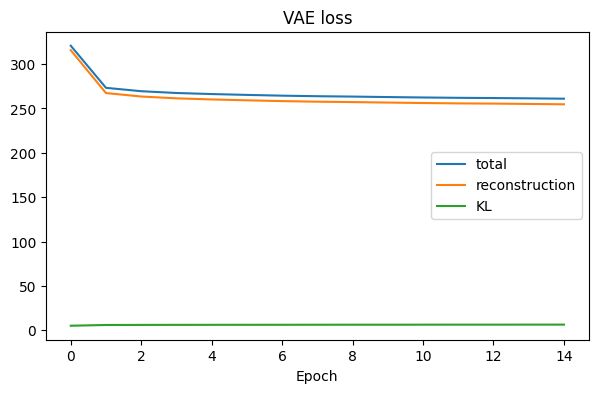

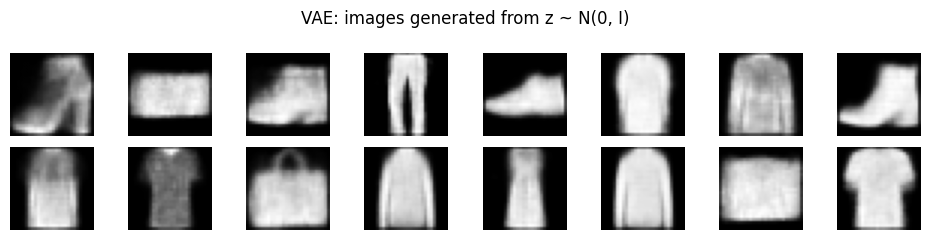

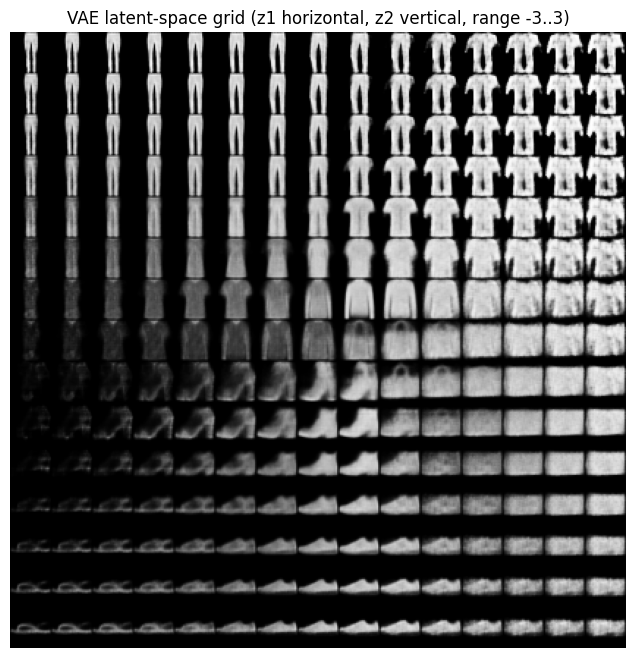

GAN epoch  1: generator loss=0.833  discriminator loss=1.190


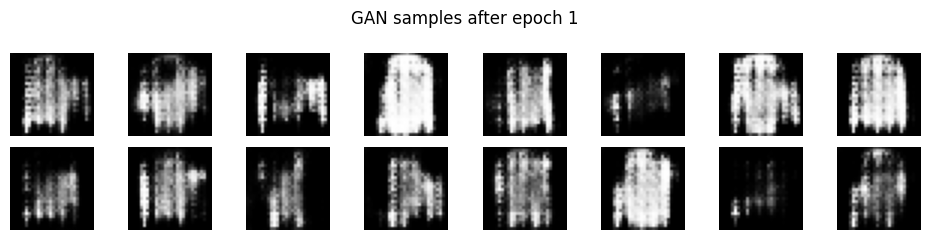

GAN epoch  2: generator loss=1.005  discriminator loss=1.086
GAN epoch  3: generator loss=1.108  discriminator loss=1.039
GAN epoch  4: generator loss=0.988  discriminator loss=1.153
GAN epoch  5: generator loss=0.944  discriminator loss=1.179


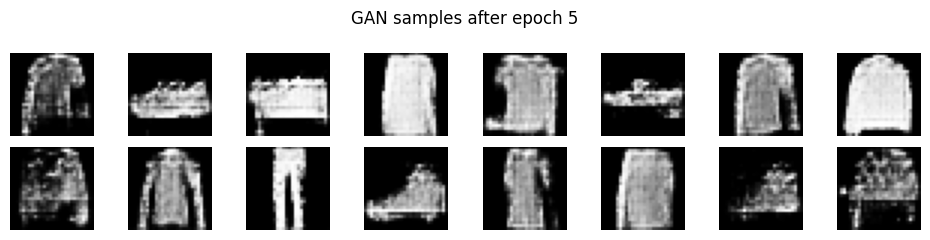

GAN epoch  6: generator loss=0.927  discriminator loss=1.191
GAN epoch  7: generator loss=0.914  discriminator loss=1.208
GAN epoch  8: generator loss=0.902  discriminator loss=1.216
GAN epoch  9: generator loss=0.883  discriminator loss=1.229
GAN epoch 10: generator loss=0.877  discriminator loss=1.240


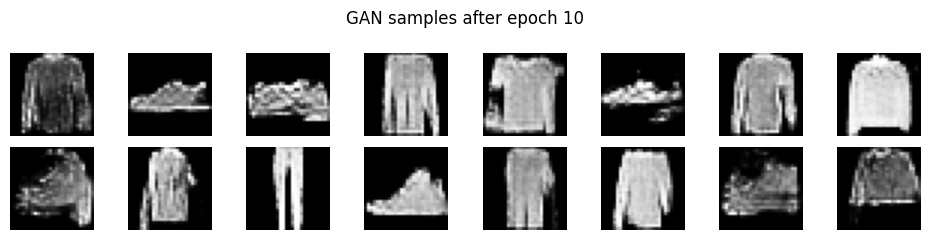

GAN epoch 11: generator loss=0.858  discriminator loss=1.257
GAN epoch 12: generator loss=0.856  discriminator loss=1.256
GAN epoch 13: generator loss=0.849  discriminator loss=1.262
GAN epoch 14: generator loss=0.854  discriminator loss=1.259
GAN epoch 15: generator loss=0.854  discriminator loss=1.261


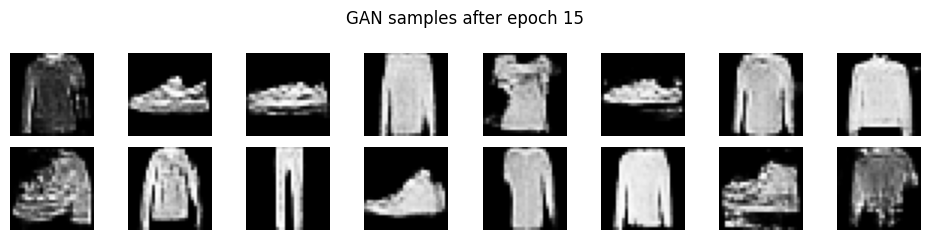

GAN epoch 16: generator loss=0.854  discriminator loss=1.260
GAN epoch 17: generator loss=0.857  discriminator loss=1.259
GAN epoch 18: generator loss=0.859  discriminator loss=1.258
GAN epoch 19: generator loss=0.854  discriminator loss=1.262
GAN epoch 20: generator loss=0.857  discriminator loss=1.263


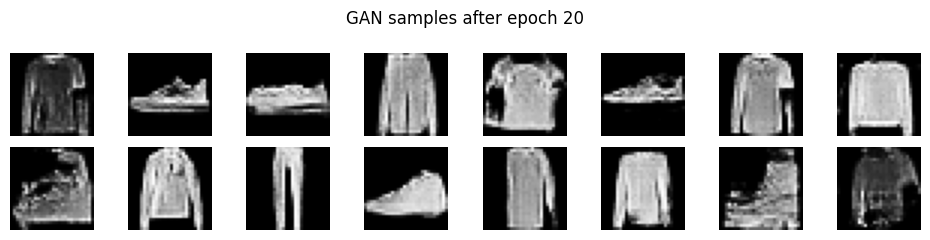

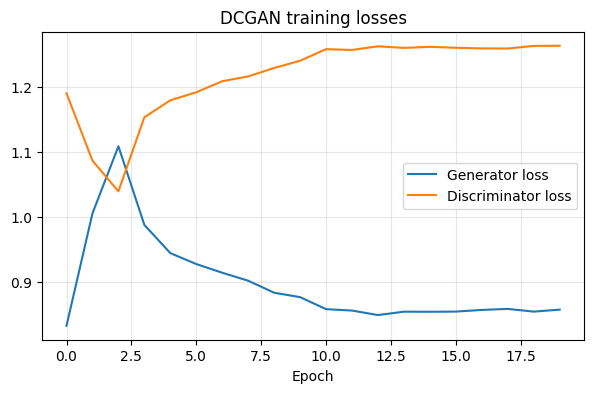

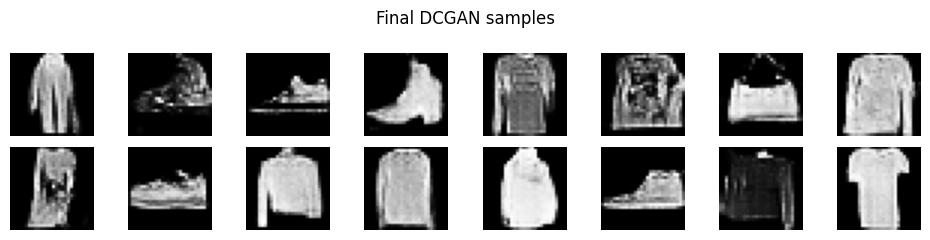

Saved: vae_decoder.keras, gan_generator.keras and gan_samples/*.png  (Experiment 30 uses the two models)


In [5]:
"""Experiment 29: VAE / GAN Sample Generation (Fashion-MNIST)"""
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

np.random.seed(42); tf.random.set_seed(42)
EPOCHS_VAE, EPOCHS_GAN, BATCH = 15, 20, 128
LATENT_VAE, LATENT_GAN = 2, 100              # 2-D latent space lets us plot a latent grid
SAVE_EVERY = 5                               # save GAN sample images every 5 epochs
os.makedirs("gan_samples", exist_ok=True)

# ---------------- Data: Fashion-MNIST (28x28 grayscale) ----------------
CLASS_NAMES = ["T-shirt", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
def load_fashion():
    try:
        (x, y), _ = keras.datasets.fashion_mnist.load_data()
        return x[..., None].astype("float32") / 255.0
    except Exception as e:                                             # offline stand-in so that the code can still run
        print("WARNING: Fashion-MNIST not available (", type(e).__name__, ") -> using scikit-learn digits as a stand-in.")
        from sklearn.datasets import load_digits
        from scipy.ndimage import zoom
        d = np.stack([zoom(im / 16.0, 3.5, order=1) for im in load_digits().images])
        return np.clip(d, 0, 1)[..., None].astype("float32")

x_train = load_fashion()
print("Training images:", x_train.shape)
ds01 = tf.data.Dataset.from_tensor_slices(x_train).shuffle(10000).batch(BATCH, drop_remainder=True)       # [0,1] for the VAE
ds11 = tf.data.Dataset.from_tensor_slices(x_train * 2 - 1).shuffle(10000).batch(BATCH, drop_remainder=True)  # [-1,1] for the GAN

def show_grid(images, n_rows, n_cols, title, path=None):
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 1.2, n_rows * 1.2))
    for a, im in zip(axes.ravel(), images):
        a.imshow(np.squeeze(im), cmap="gray"); a.axis("off")
    plt.suptitle(title); plt.tight_layout()
    if path: plt.savefig(path, dpi=80)
    plt.show()

# =============================== VAE ===============================
# ---------------- Task 1: encoder, reparameterisation, decoder ----------------
enc_in = keras.Input((28, 28, 1))
x = layers.Conv2D(32, 3, strides=2, padding="same", activation="relu")(enc_in)
x = layers.Conv2D(64, 3, strides=2, padding="same", activation="relu")(x)
x = layers.Dense(128, activation="relu")(layers.Flatten()(x))
z_mean = layers.Dense(LATENT_VAE, name="z_mean")(x)
z_log_var = layers.Dense(LATENT_VAE, name="z_log_var")(x)
encoder = keras.Model(enc_in, [z_mean, z_log_var], name="encoder")

dec_in = keras.Input((LATENT_VAE,))
y = layers.Dense(7 * 7 * 64, activation="relu")(dec_in)
y = layers.Reshape((7, 7, 64))(y)
y = layers.Conv2DTranspose(64, 3, strides=2, padding="same", activation="relu")(y)
y = layers.Conv2DTranspose(32, 3, strides=2, padding="same", activation="relu")(y)
dec_out = layers.Conv2DTranspose(1, 3, padding="same", activation="sigmoid")(y)
decoder = keras.Model(dec_in, dec_out, name="decoder")

vae_opt = keras.optimizers.Adam(1e-3)

@tf.function
def vae_step(batch):
    with tf.GradientTape() as tape:
        mu, log_var = encoder(batch, training=True)
        eps = tf.random.normal(tf.shape(mu))
        z = mu + tf.exp(0.5 * log_var) * eps                                      # reparameterisation trick
        recon = decoder(z, training=True)
        rec_loss = tf.reduce_mean(tf.reduce_sum(keras.losses.binary_crossentropy(batch, recon), axis=(1, 2)))
        kl = tf.reduce_mean(-0.5 * tf.reduce_sum(1 + log_var - tf.square(mu) - tf.exp(log_var), axis=1))
        loss = rec_loss + kl                                                      # reconstruction + KL
    vars_ = encoder.trainable_variables + decoder.trainable_variables
    vae_opt.apply_gradients(zip(tape.gradient(loss, vars_), vars_))
    return loss, rec_loss, kl

vae_hist = []
for ep in range(1, EPOCHS_VAE + 1):
    vals = np.array([[float(t) for t in vae_step(b)] for b in ds01]).mean(axis=0)
    vae_hist.append(vals)
    print(f"VAE epoch {ep:2d}: total={vals[0]:.2f}  reconstruction={vals[1]:.2f}  KL={vals[2]:.2f}")
vae_hist = np.array(vae_hist)
plt.figure(figsize=(7, 4)); plt.plot(vae_hist[:, 0], label="total"); plt.plot(vae_hist[:, 1], label="reconstruction"); plt.plot(vae_hist[:, 2], label="KL")
plt.xlabel("Epoch"); plt.title("VAE loss"); plt.legend(); plt.show()

# ---------------- Task 2: sample the latent space + 2-D latent grid ----------------
samples = decoder(tf.random.normal((16, LATENT_VAE))).numpy()
show_grid(samples, 2, 8, "VAE: images generated from z ~ N(0, I)")

n = 15; grid = np.linspace(-3, 3, n)
canvas = np.zeros((28 * n, 28 * n))
for i, yi in enumerate(grid[::-1]):
    for j, xj in enumerate(grid):
        canvas[i * 28:(i + 1) * 28, j * 28:(j + 1) * 28] = decoder(np.array([[xj, yi]], dtype="float32")).numpy()[0, :, :, 0]
plt.figure(figsize=(8, 8)); plt.imshow(canvas, cmap="gray"); plt.axis("off")
plt.title("VAE latent-space grid (z1 horizontal, z2 vertical, range -3..3)"); plt.show()
decoder.save("vae_decoder.keras")

# =============================== DCGAN ===============================
# ---------------- Task 3: generator and discriminator ----------------
generator = keras.Sequential([
    layers.Input((LATENT_GAN,)),
    layers.Dense(7 * 7 * 128, use_bias=False), layers.BatchNormalization(), layers.LeakyReLU(0.2), layers.Reshape((7, 7, 128)),
    layers.Conv2DTranspose(64, 5, strides=1, padding="same", use_bias=False), layers.BatchNormalization(), layers.LeakyReLU(0.2),
    layers.Conv2DTranspose(32, 5, strides=2, padding="same", use_bias=False), layers.BatchNormalization(), layers.LeakyReLU(0.2),
    layers.Conv2DTranspose(1, 5, strides=2, padding="same", activation="tanh"),
], name="generator")
discriminator = keras.Sequential([
    layers.Input((28, 28, 1)),
    layers.Conv2D(64, 5, strides=2, padding="same"), layers.LeakyReLU(0.2), layers.Dropout(0.3),
    layers.Conv2D(128, 5, strides=2, padding="same"), layers.LeakyReLU(0.2), layers.Dropout(0.3),
    layers.Flatten(), layers.Dense(1),
], name="discriminator")

bce = keras.losses.BinaryCrossentropy(from_logits=True)
g_opt = keras.optimizers.Adam(2e-4, beta_1=0.5); d_opt = keras.optimizers.Adam(2e-4, beta_1=0.5)

@tf.function
def gan_step(real):
    noise = tf.random.normal((tf.shape(real)[0], LATENT_GAN))
    with tf.GradientTape() as gt, tf.GradientTape() as dt:
        fake = generator(noise, training=True)
        real_out, fake_out = discriminator(real, training=True), discriminator(fake, training=True)
        g_loss = bce(tf.ones_like(fake_out), fake_out)                                       # generator wants D(fake) = 1
        d_loss = bce(tf.ones_like(real_out), real_out) + bce(tf.zeros_like(fake_out), fake_out)
    g_opt.apply_gradients(zip(gt.gradient(g_loss, generator.trainable_variables), generator.trainable_variables))
    d_opt.apply_gradients(zip(dt.gradient(d_loss, discriminator.trainable_variables), discriminator.trainable_variables))
    return g_loss, d_loss

# ---------------- Task 4: train and save generated images every few epochs ----------------
fixed_noise = tf.random.normal((16, LATENT_GAN))
gan_hist = []
for ep in range(1, EPOCHS_GAN + 1):
    vals = np.array([[float(t) for t in gan_step(b)] for b in ds11]).mean(axis=0)
    gan_hist.append(vals)
    print(f"GAN epoch {ep:2d}: generator loss={vals[0]:.3f}  discriminator loss={vals[1]:.3f}")
    if ep % SAVE_EVERY == 0 or ep == 1:
        imgs = (generator(fixed_noise, training=False).numpy() + 1) / 2
        show_grid(imgs, 2, 8, f"GAN samples after epoch {ep}", path=f"gan_samples/epoch_{ep:03d}.png")
gan_hist = np.array(gan_hist)
generator.save("gan_generator.keras")

# ---------------- Task 5: loss curves ----------------
plt.figure(figsize=(7, 4)); plt.plot(gan_hist[:, 0], label="Generator loss"); plt.plot(gan_hist[:, 1], label="Discriminator loss")
plt.xlabel("Epoch"); plt.title("DCGAN training losses"); plt.legend(); plt.grid(alpha=0.3); plt.show()

fake = (generator(tf.random.normal((16, LATENT_GAN)), training=False).numpy() + 1) / 2
show_grid(fake, 2, 8, "Final DCGAN samples")
print("Saved: vae_decoder.keras, gan_generator.keras and gan_samples/*.png  (Experiment 30 uses the two models)")

Classifier test accuracy: 0.8820


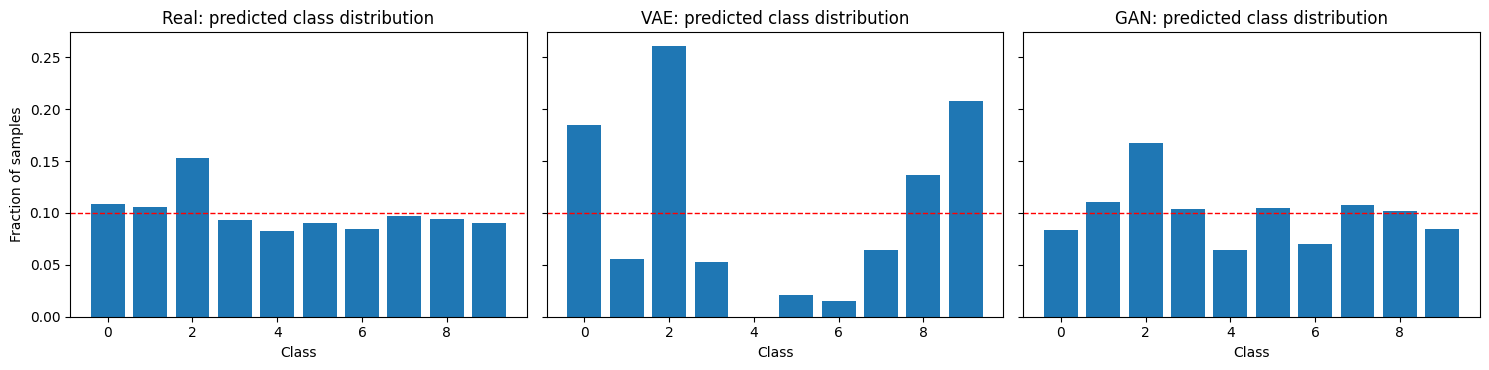

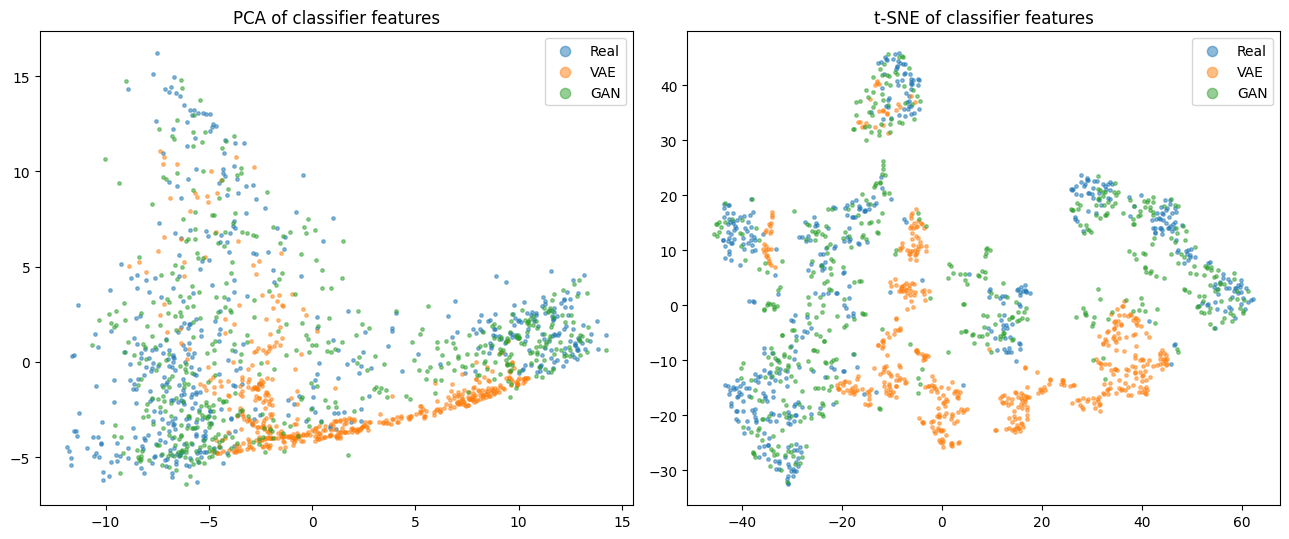

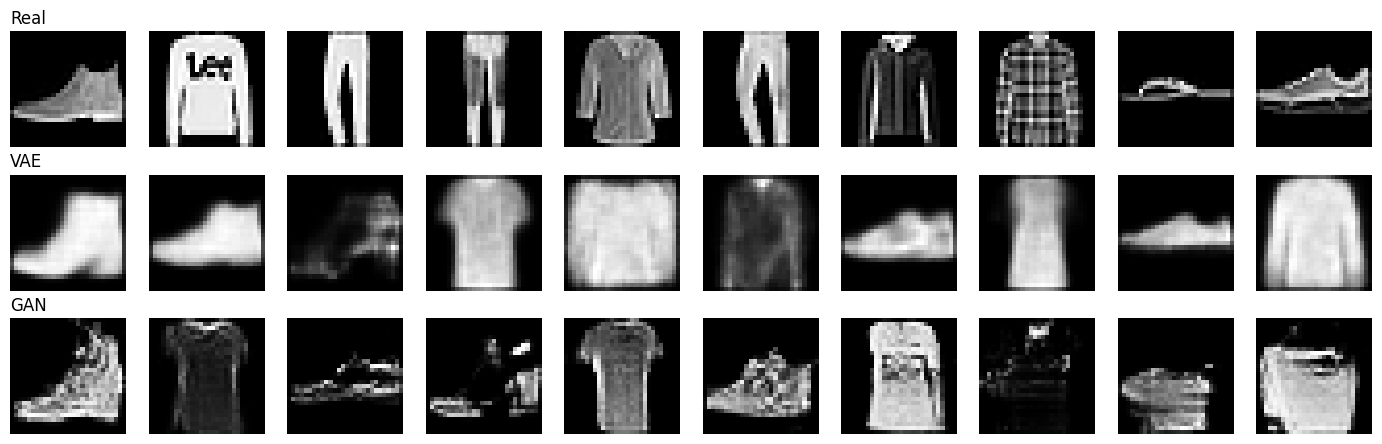


        Inception Score  FID (lower=better)  Class entropy (0-1)  Classes covered  Max class share  Mean pairwise distance  Mean confidence
Model                                                                                                                                     
Real             7.302               1.128                0.993               10            0.153                  11.262            0.892
VAE              3.543              79.318                0.825                9            0.261                   8.867            0.712
GAN              5.537               3.952                0.985               10            0.167                  10.693            0.787

Best FID: GAN | best Inception Score: GAN | most diverse (class entropy): GAN
Points (FID x2, IS x1, diversity x1): {'VAE': 0.0, 'GAN': 4.0}
RECOMMENDATION: GAN.
Rationale: FID compares the whole feature distribution to real data (most important); Inception Score rewards confident, varied samples; cla

In [6]:
"""Experiment 30: Generative Model Output Comparison and Evaluation (VAE vs GAN)
Run Experiment 29 first: it saves vae_decoder.keras and gan_generator.keras in the working folder."""
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from scipy import linalg
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

np.random.seed(42); tf.random.set_seed(42)
N = 1000
LATENT_VAE, LATENT_GAN = 2, 100

def load_fashion():
    try:
        (x, y), (xt, yt) = keras.datasets.fashion_mnist.load_data()
        return x[..., None] / 255.0, y, xt[..., None] / 255.0, yt
    except Exception as e:
        print("WARNING: Fashion-MNIST not available (", type(e).__name__, ") -> using scikit-learn digits as a stand-in.")
        from sklearn.datasets import load_digits
        from scipy.ndimage import zoom
        d = load_digits(); im = np.clip(np.stack([zoom(i / 16.0, 3.5, order=1) for i in d.images]), 0, 1)[..., None]
        cut = int(0.75 * len(im)); return im[:cut], d.target[:cut], im[cut:], d.target[cut:]

x_train, y_train, x_test, y_test = [a.astype("float32") if a.dtype.kind == "f" else a for a in load_fashion()]

# ---------------- Task 1: generate 1,000 samples from each model ----------------
try:
    decoder = keras.models.load_model("vae_decoder.keras"); generator = keras.models.load_model("gan_generator.keras")
except Exception as e:
    raise SystemExit("Could not load vae_decoder.keras / gan_generator.keras - run Experiment 29 first in this folder.")
vae_samples = decoder(tf.random.normal((N, LATENT_VAE))).numpy()
gan_samples = (generator(tf.random.normal((N, LATENT_GAN)), training=False).numpy() + 1) / 2
real_samples = x_test[:N]
sets = {"Real": real_samples, "VAE": vae_samples, "GAN": gan_samples}

# ---------------- Task 2: classifier-based Inception Score and FID ----------------
clf_in = keras.Input((28, 28, 1))
h = layers.Conv2D(32, 3, activation="relu")(clf_in); h = layers.MaxPooling2D()(h)
h = layers.Conv2D(64, 3, activation="relu")(h); h = layers.MaxPooling2D()(h)
feat = layers.Dense(64, activation="relu", name="features")(layers.Flatten()(h))
clf_out = layers.Dense(10, activation="softmax")(feat)
classifier = keras.Model(clf_in, clf_out)
classifier.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
classifier.fit(x_train, y_train, epochs=4, batch_size=128, verbose=0)
print(f"Classifier test accuracy: {classifier.evaluate(x_test, y_test, verbose=0)[1]:.4f}")
feature_extractor = keras.Model(clf_in, feat)

def inception_score(probs, eps=1e-12):
    py = probs.mean(axis=0, keepdims=True)
    return float(np.exp(np.mean(np.sum(probs * (np.log(probs + eps) - np.log(py + eps)), axis=1))))

def fid(f1, f2):
    mu1, mu2 = f1.mean(0), f2.mean(0); s1, s2 = np.cov(f1, rowvar=False), np.cov(f2, rowvar=False)
    s1 = s1 + 1e-6 * np.eye(len(s1)); s2 = s2 + 1e-6 * np.eye(len(s2))       # numerical stability
    covmean = linalg.sqrtm(s1 @ s2)
    if np.iscomplexobj(covmean): covmean = covmean.real
    return float(np.sum((mu1 - mu2) ** 2) + np.trace(s1 + s2 - 2 * covmean))

probs = {k: classifier.predict(v, verbose=0) for k, v in sets.items()}
feats = {k: feature_extractor.predict(v, verbose=0) for k, v in sets.items()}
# Reference real set for FID: use a DIFFERENT 1,000 real images from the test set (so Real-vs-Real is a sensible baseline)
ref_feats = feature_extractor.predict(x_test[N:2 * N] if len(x_test) >= 2 * N else x_train[:N], verbose=0)

# ---------------- Task 3: diversity and mode collapse ----------------
rows = []
for k in sets:
    pred = probs[k].argmax(axis=1)
    dist = np.bincount(pred, minlength=10) / len(pred)
    ent = -np.sum(dist[dist > 0] * np.log(dist[dist > 0])) / np.log(10)          # 1.0 = perfectly uniform over 10 classes
    idx = np.random.choice(len(sets[k]), 200, replace=False); flat = sets[k][idx].reshape(200, -1)
    pair = np.mean(np.linalg.norm(flat[:, None] - flat[None], axis=2))
    rows.append({"Model": k, "Inception Score": inception_score(probs[k]), "FID (lower=better)": fid(feats[k], ref_feats),
                 "Class entropy (0-1)": ent, "Classes covered": int((dist > 0.01).sum()), "Max class share": dist.max(),
                 "Mean pairwise distance": pair, "Mean confidence": probs[k].max(axis=1).mean()})

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
for a, k in zip(ax, sets):
    a.bar(range(10), np.bincount(probs[k].argmax(axis=1), minlength=10) / len(probs[k])); a.set_title(f"{k}: predicted class distribution")
    a.set_xlabel("Class"); a.axhline(0.1, color="r", ls="--", lw=1)
ax[0].set_ylabel("Fraction of samples"); plt.tight_layout(); plt.show()

# ---------------- Task 4: real vs generated feature distributions ----------------
M = min(500, len(real_samples))
allf = np.vstack([feats[k][:M] for k in sets]); labels = np.repeat(list(sets), M)
fig, ax = plt.subplots(1, 2, figsize=(13, 5.5))
for a, emb, title in zip(ax, [PCA(2).fit_transform(allf), TSNE(2, init="pca", random_state=0).fit_transform(allf)], ["PCA of classifier features", "t-SNE of classifier features"]):
    for k, c in zip(sets, ["tab:blue", "tab:orange", "tab:green"]):
        m = labels == k; a.scatter(emb[m, 0], emb[m, 1], s=6, alpha=0.5, c=c, label=k)
    a.set_title(title); a.legend(markerscale=3)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(3, 10, figsize=(14, 4.5))
for r, k in enumerate(sets):
    for c in range(10):
        axes[r, c].imshow(sets[k][c, :, :, 0], cmap="gray"); axes[r, c].axis("off")
    axes[r, 0].set_title(k, loc="left")
plt.tight_layout(); plt.show()

# ---------------- Task 5: table and recommendation ----------------
table = pd.DataFrame(rows).set_index("Model")
pd.set_option("display.width", 220); pd.set_option("display.max_columns", None)
print("\n", table.round(3))
table.to_csv("generative_model_metrics.csv")

cand = table.loc[["VAE", "GAN"]]
best_fid = cand["FID (lower=better)"].idxmin(); best_is = cand["Inception Score"].idxmax(); best_div = cand["Class entropy (0-1)"].idxmax()
print(f"\nBest FID: {best_fid} | best Inception Score: {best_is} | most diverse (class entropy): {best_div}")
points = pd.Series({"VAE": 0, "GAN": 0}, dtype=float)
points[best_fid] += 2; points[best_is] += 1; points[best_div] += 1            # FID counts double
rec = best_fid if points.nunique() == 1 else points.idxmax()     # tie -> lowest FID
print(f"Points (FID x2, IS x1, diversity x1): {points.to_dict()}")
print(f"RECOMMENDATION: {rec}.")
print("Rationale: FID compares the whole feature distribution to real data (most important); Inception Score rewards confident, "
      "varied samples; class entropy and the class histogram reveal mode collapse (a few classes dominating). "
      "A model with low FID but low class entropy should be treated with caution.")